# Graph Neural Networks from Scratch — Tutorial 7: GraphSAGE and Advanced Aggregation

### From full-graph training to sampling, mini-batches, and inductive learning

*🐍 Python · PyTorch · PyTorch Geometric | Intermediate*

---

## Series Roadmap

In Tutorial 1, we learned how graphs represent connected data through nodes, edges, adjacency matrices, and node features.

In Tutorial 2, we implemented a **Graph Convolutional Network (GCN) forward pass from scratch using NumPy**. In Tutorial 3, we made it trainable with **PyTorch**.

In Tutorial 4, we introduced **PyTorch Geometric (PyG)** and trained a GCN on the **Cora citation network**.

In Tutorial 5, we split a GNN layer into **message, aggregate, and update**, and built our own GraphSAGE-style layer with mean aggregation.

In Tutorial 6, we let the network **learn** neighbour weights with **graph attention**.

Every model so far has had two things in common:

1. It processes the **whole graph** in every forward pass.
2. It is trained and evaluated on the **same graph**, with all nodes visible during training.

Both are fine for Cora's 2,708 nodes. Neither holds for a social network with millions of users, a citation graph that grows every day, or a new mesh that the model has never seen.

**GraphSAGE** (*Graph SAmple and aggreGatE*) addresses both. It learns an **aggregation function** instead of a fixed set of node embeddings, and it **samples** a bounded number of neighbours so that computation stays manageable. In this tutorial, we will compare aggregators, build a pooling aggregator, implement neighbour sampling from scratch, train with mini-batches, and test the model on nodes it **never saw during training**.

| # | Tutorial | Focus | Status |
|---|---|---|---|
| 1 | Graph Fundamentals and Representations | nodes, edges, adjacency matrices, graph features | ✅ |
| 2 | Graph Convolutional Networks from Scratch | propagation, normalization, NumPy implementation | ✅ |
| 3 | Training a GCN with PyTorch | learnable parameters, backpropagation, node classification | ✅ |
| 4 | PyTorch Geometric and the Cora Dataset | PyG, real-world graph data, practical GCN implementation | ✅ |
| 5 | Message Passing Neural Networks | message, aggregate, update, custom GNN layers | ✅ |
| 6 | Graph Attention Networks (GAT) | learned attention, neighbour weighting, multi-head attention | ✅ |
| **7** | **GraphSAGE and Advanced Aggregation** | **aggregators, neighbour sampling, mini-batches, inductive learning** | **📍 You are here** |
| 8 | Graph-Level Learning | graph classification and regression | Planned |
| 9 | GNNs for Mesh-Based Systems | mesh connectivity, geometric features, scientific data | Planned |
| 10 | GNNs for Scientific Machine Learning | surrogate modelling and engineering applications | Planned |

The goal is to progress from understanding graph representations and implementing GNNs from scratch to using practical tools for learning from complex connected systems, including computational meshes and physical systems.

---

In this tutorial, we will explore the essential components of GraphSAGE:

- Transductive vs. inductive graph learning.
- Mean, max, and sum aggregation, and what each one can and cannot distinguish.
- A trainable **pooling** aggregator built from scratch.
- Why the receptive field explodes with depth, and how **neighbour sampling** bounds it.
- Implementing neighbour sampling and **mini-batch training** with plain PyTorch.
- Verifying our layers against PyG's `SAGEConv`.
- Training GraphSAGE on Cora with the Tutorial 4–6 workflow.
- An **inductive experiment**: predicting labels for nodes that were hidden during training.

We will begin with the four-node graph from Tutorials 5 and 6. Then, we will scale the same ideas up to Cora.

## The learning process

Our workflow in this tutorial will follow this sequence:

```text
        Small Example Graph
                |
                v
   Compare Aggregators (mean / max / sum)
                |
                v
    Pooling Aggregator from Scratch
                |
                v
   Neighbour Sampling from Scratch
                |
                v
    SAGEConv (verify against ours)
                |
                v
    Cora: Full-Batch Training → Test
                |
                v
   Mini-Batch Training with Sampling
                |
                v
   Inductive Test: Unseen Nodes
```

The layer itself is the one from Tutorial 5. What is new is **how we feed the graph to it**: sampled neighbourhoods, mini-batches, and graphs that change between training and inference.

> **New to sampling?** Don't worry. Neighbour sampling simply means "for each node, keep at most $k$ randomly chosen neighbours". We will implement it in a few lines with the same tensor tools we used in Tutorials 5 and 6.
>
> If you're interested in scientific machine learning, CFD, or computational mechanics, pay attention to the inductive experiment. A model that learns a *rule* for combining neighbours, rather than one embedding per node, can in principle be applied to a mesh it has never seen, a different resolution or a different geometry. That is exactly what a mesh-based surrogate model needs.

**Let's move from training on one fixed graph to learning rules that transfer to new nodes and larger graphs.**

## 1. Why GraphSAGE?

### Transductive vs. inductive learning

| Setting | During training | At inference |
|---|---|---|
| **Transductive** | the whole graph (all nodes and edges) is visible; only some labels are used | predict labels for nodes of the **same** graph |
| **Inductive** | only part of the graph (or some graphs) is visible | predict for **new nodes or new graphs** |

All our Cora experiments so far were transductive: test nodes were in the graph during training, even though their labels were hidden.

Some graph methods learn **one embedding vector per node**. Such a model has nothing to offer a node that did not exist during training. GraphSAGE instead learns a **function** of a node's features and its neighbourhood. Any node with features and neighbours, new or old, can be passed through that function.

### Scale

A 2-layer GNN needs each node's 2-hop neighbourhood. In a large graph, a single high-degree node can pull in a large part of the graph. GraphSAGE caps this by **sampling** a fixed number of neighbours per layer.

## 2. Setup

We use the same environment as Tutorials 4–6. If PyG is missing, the cell below installs it.

In [1]:
import sys
import subprocess

import torch
import torch.nn as nn
import torch.nn.functional as F

print("PyTorch:", torch.__version__)

try:
    import torch_geometric
except ImportError:
    print("PyTorch Geometric is not installed. Installing it now...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "torch-geometric"])
    import torch_geometric
    print("Installation complete.")

print("PyG:", torch_geometric.__version__)

torch.manual_seed(7)

PyTorch: 2.11.0+cu130


/home/rohit/venvs/py13env/lib64/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyG: 2.8.1


# Part I — Aggregators on a small graph

## 3. The GraphSAGE update

GraphSAGE uses the update from Tutorial 5, with a **configurable aggregator**:

$$
\mathbf h_{\mathcal N(i)}=\operatorname{AGGREGATE}\left(\{\mathbf h_j: j\in\mathcal N(i)\}\right)
$$

$$
\mathbf h_i'=\sigma\left(\mathbf W\left[\ \mathbf h_i\ \Vert\ \mathbf h_{\mathcal N(i)}\ \right]+\mathbf b\right)
$$

The node's own representation $\mathbf h_i$ is kept **separate** from the neighbourhood summary. This is a key difference from GCN, where the node is just one more term inside the sum (via the self-loop).

The original GraphSAGE paper compares several aggregators:

| Aggregator | Formula | Learnable? |
|---|---|---|
| Mean | $\frac{1}{\lvert\mathcal N(i)\rvert}\sum_j\mathbf h_j$ | ❌ |
| Max | $\max_j\mathbf h_j$ (element-wise) | ❌ |
| Sum | $\sum_j\mathbf h_j$ | ❌ |
| **Pooling** | $\max_j\operatorname{ReLU}(\mathbf W_{\text{pool}}\mathbf h_j+\mathbf b_{\text{pool}})$ | ✅ |
| LSTM | LSTM over a random ordering of neighbours | ✅ (not permutation-invariant) |

## 4. Our example graph

We reuse the four-node graph from Tutorials 5 and 6:

```text
    0 ------ 1
     \      /
      \    /
        2 ------ 3
```

In [2]:
# Undirected edges: 0--1, 0--2, 1--2, 2--3
edge_index = torch.tensor([
    [0, 1, 0, 2, 1, 2, 2, 3],  # source nodes (j)
    [1, 0, 2, 0, 2, 1, 3, 2]   # destination nodes (i)
], dtype=torch.long)

x = torch.tensor([
    [1.0, 0.0],   # node 0
    [0.0, 1.0],   # node 1
    [1.0, 1.0],   # node 2
    [2.0, 0.0]    # node 3
])
num_nodes = x.size(0)

print("Node features:", x.shape)
print("Edge index:", edge_index.shape)

Node features: torch.Size([4, 2])
Edge index: torch.Size([2, 8])


## 5. Three aggregators with plain PyTorch

We already know `index_add_` from Tutorial 5 (sum and mean) and `scatter_reduce_` from Tutorial 6 (max). One function covers all three.

In [3]:
def aggregate(x, edge_index, how="mean"):
    """Aggregate source-node features at each destination node."""
    src, dst = edge_index
    num_nodes, num_features = x.shape
    messages = x[src]                                   # one row per edge

    if how in ("sum", "mean"):
        out = torch.zeros(num_nodes, num_features, dtype=x.dtype, device=x.device)
        out.index_add_(0, dst, messages)
        if how == "mean":
            counts = torch.zeros(num_nodes, 1, dtype=x.dtype, device=x.device)
            counts.index_add_(0, dst, torch.ones(dst.numel(), 1, dtype=x.dtype, device=x.device))
            out = out / counts.clamp(min=1)
        return out

    if how == "max":
        out = torch.zeros(num_nodes, num_features, dtype=x.dtype, device=x.device)
        index = dst[:, None].expand(-1, num_features)
        out.scatter_reduce_(0, index, messages, reduce="amax", include_self=False)
        return out   # nodes without neighbours keep 0

    raise ValueError(f"Unknown aggregation: {how}")

for how in ["mean", "max", "sum"]:
    print(f"{how.upper()} aggregation:\n{aggregate(x, edge_index, how)}\n")

MEAN aggregation:
tensor([[0.5000, 1.0000],
        [1.0000, 0.5000],
        [1.0000, 0.3333],
        [1.0000, 1.0000]])

MAX aggregation:
tensor([[1., 1.],
        [1., 1.],
        [2., 1.],
        [1., 1.]])

SUM aggregation:
tensor([[1., 2.],
        [2., 1.],
        [3., 1.],
        [1., 1.]])



Check node 2 by hand. Its neighbours are 0, 1, and 3 with features $[1,0]$, $[0,1]$, $[2,0]$:

| Aggregator | Node 2 |
|---|---|
| Mean | $[1,\ 0.333]$ |
| Max | $[2,\ 1]$ |
| Sum | $[3,\ 1]$ |

## 6. What can each aggregator distinguish?

Different neighbourhoods can produce the **same** aggregate. Let's build three tiny "star" neighbourhoods with one-dimensional features and see which aggregator can tell them apart:

| Pair | Neighbourhood A | Neighbourhood B |
|---|---|---|
| 1 | $\{1\}$ | $\{1,\ 1\}$ |
| 2 | $\{1,\ 3\}$ | $\{2,\ 2\}$ |
| 3 | $\{0,\ 4\}$ | $\{1,\ 3\}$ |

In [4]:
def star_aggregate(neighbour_values, how):
    """Aggregate a list of scalar neighbour features into one centre node (index 0)."""
    feats = torch.tensor([[0.0]] + [[v] for v in neighbour_values])
    k = len(neighbour_values)
    ei = torch.stack([torch.arange(1, k + 1), torch.zeros(k, dtype=torch.long)])
    return aggregate(feats, ei, how)[0, 0].item()

pairs = [([1], [1, 1]), ([1, 3], [2, 2]), ([0, 4], [1, 3])]

print(f"{'A':>8} {'B':>8} | {'mean':>11} | {'max':>11} | {'sum':>11}")
print("-" * 56)
for a, b in pairs:
    row = []
    for how in ["mean", "max", "sum"]:
        va, vb = star_aggregate(a, how), star_aggregate(b, how)
        row.append(f"{va:g} vs {vb:g}" + (" ✗" if va == vb else " ✓"))
    print(f"{str(a):>8} {str(b):>8} | " + " | ".join(f"{r:>11}" for r in row))

       A        B |        mean |         max |         sum
--------------------------------------------------------
     [1]   [1, 1] |    1 vs 1 ✗ |    1 vs 1 ✗ |    1 vs 2 ✓
  [1, 3]   [2, 2] |    2 vs 2 ✗ |    3 vs 2 ✓ |    4 vs 4 ✗
  [0, 4]   [1, 3] |    2 vs 2 ✗ |    4 vs 3 ✓ |    4 vs 4 ✗


✓ = the aggregator separates the two neighbourhoods, ✗ = it cannot.

- **Mean** loses the **number** of neighbours (pair 1).
- **Max** keeps only the extremes; it loses counts and middle values (pairs 1 and 3).
- **Sum** distinguishes all three pairs here, but its scale grows with degree, which can make training harder on graphs with very different degrees.

No aggregator is best in every case. The right choice depends on whether degree, extremes, or proportions matter for the task.

## 🧪 Hands-on Exercise 1

1. Find a pair of neighbourhoods that **max** cannot distinguish but **mean** can.
2. Is there a pair that **none** of the three aggregators can distinguish?
3. For a citation graph, which information matters more: the *proportion* of neighbours on each topic, or the *number*? Which aggregator matches that?

In [5]:
# TODO: test your own neighbourhood pairs.

# a, b = [...], [...]
# for how in ["mean", "max", "sum"]:
#     print(how, star_aggregate(a, how), star_aggregate(b, how))

# Part II — Trainable aggregators from scratch

## 7. The mean GraphSAGE layer

This is the layer from Tutorial 5, now using our general `aggregate()` function so that the aggregator can be swapped.

In [5]:
class SAGELayer(nn.Module):
    """GraphSAGE layer with a fixed aggregator, written with plain PyTorch."""

    def __init__(self, in_channels, out_channels, aggr="mean"):
        super().__init__()
        self.aggr = aggr
        self.linear = nn.Linear(2 * in_channels, out_channels)

    def forward(self, x, edge_index):
        h_neigh = aggregate(x, edge_index, self.aggr)        # aggregate
        combined = torch.cat([x, h_neigh], dim=1)             # [h_i || h_N(i)]
        return self.linear(combined)                          # update

sage_mean = SAGELayer(2, 4, aggr="mean")
print(sage_mean)
print("Output shape:", sage_mean(x, edge_index).shape)

SAGELayer(
  (linear): Linear(in_features=4, out_features=4, bias=True)
)
Output shape: torch.Size([4, 4])


## 8. The pooling aggregator

Max aggregation only sees the raw features. The **pooling** aggregator first passes every neighbour through a small shared neural network, then takes the element-wise maximum:

$$
\mathbf h_{\mathcal N(i)}=\max_{j\in\mathcal N(i)}\operatorname{ReLU}\left(\mathbf W_{\text{pool}}\mathbf h_j+\mathbf b_{\text{pool}}\right)
$$

```text
 h_j1 ─▶ [W_pool, ReLU] ─▶ p_j1 ─┐
 h_j2 ─▶ [W_pool, ReLU] ─▶ p_j2 ─┼─▶ element-wise max ─▶ h_N(i)
 h_j3 ─▶ [W_pool, ReLU] ─▶ p_j3 ─┘
         (shared weights)
```

The network can learn **which feature combinations** are worth detecting, and the max reports whether *any* neighbour shows them. Because the same network is applied to every neighbour and max ignores order, the result is still permutation-invariant.

We transform each **node** once, then aggregate. This is cheaper than transforming each edge and gives the same result, because every edge from node $j$ carries the same transformed vector.

In [6]:
class PoolSAGELayer(nn.Module):
    """GraphSAGE layer with a learnable pooling aggregator, written with plain PyTorch."""

    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.pool = nn.Linear(in_channels, in_channels)          # W_pool, b_pool
        self.linear = nn.Linear(2 * in_channels, out_channels)   # W, b

    def forward(self, x, edge_index):
        p = F.relu(self.pool(x))                                 # transform every node once
        h_neigh = aggregate(p, edge_index, "max")                # element-wise max over neighbours
        combined = torch.cat([x, h_neigh], dim=1)
        return self.linear(combined)

sage_pool = PoolSAGELayer(2, 4)
print(sage_pool)
print("Output shape:", sage_pool(x, edge_index).shape)

PoolSAGELayer(
  (pool): Linear(in_features=2, out_features=2, bias=True)
  (linear): Linear(in_features=4, out_features=4, bias=True)
)
Output shape: torch.Size([4, 4])


## 9. Count the learnable parameters

| Layer | Parameters (in $=2$, out $=4$) |
|---|---|
| Mean | $4\cdot(2\cdot 2)+4=20$ |
| Pooling | $\underbrace{2\cdot 2+2}_{\text{pool}}+20=26$ |

In [7]:
print("Mean layer parameters:   ", sum(p.numel() for p in sage_mean.parameters()))
print("Pooling layer parameters:", sum(p.numel() for p in sage_pool.parameters()))

Mean layer parameters:    20
Pooling layer parameters: 26


## 🧪 Hands-on Exercise 2

Show that both layers are **permutation-invariant**: shuffle the columns of `edge_index` with `torch.randperm` and check that the outputs do not change.

Then think: would an LSTM aggregator pass this test? Why did the GraphSAGE authors feed it a random neighbour ordering?

In [9]:
# TODO: shuffle the edge order and compare outputs.

# perm = torch.randperm(edge_index.size(1))
# shuffled = edge_index[:, perm]
# print((sage_pool(x, edge_index) - sage_pool(x, shuffled)).abs().max().item())

# Part III — Neighbour sampling from scratch

## 10. The receptive field explodes

In Tutorial 5, we measured the receptive field of a single Cora node. Let's look at the whole graph: how many nodes does a $K$-layer GNN need to compute **one** prediction?

In [9]:
from torch_geometric.datasets import Planetoid
from torch_geometric.utils import k_hop_subgraph, degree

dataset = Planetoid(root="data/Planetoid", name="Cora")
data = dataset[0]

deg = degree(data.edge_index[1], num_nodes=data.num_nodes)
print(f"Node degree: mean = {deg.mean():.1f}, max = {int(deg.max())}")

hub = int(deg.argmax())
print(f"\nReceptive field of the highest-degree node ({hub}):")
for k in [1, 2, 3]:
    subset, _, _, _ = k_hop_subgraph(hub, k, data.edge_index, num_nodes=data.num_nodes)
    print(f"  {k} layer(s): {subset.numel():5d} nodes  ({subset.numel() / data.num_nodes:.0%} of the graph)")

Node degree: mean = 3.9, max = 168

Receptive field of the highest-degree node (1358):
  1 layer(s):   169 nodes  (6% of the graph)
  2 layer(s):   426 nodes  (16% of the graph)
  3 layer(s):   899 nodes  (33% of the graph)


With three layers, one prediction for the hub node needs a large share of Cora. On a graph with millions of nodes, a few hub nodes would make every mini-batch nearly as expensive as the full graph.

**Neighbour sampling** fixes the cost. With fan-outs $[k_1, k_2]$, a 2-layer model touches at most

$$
1+k_1+k_1k_2
$$

nodes per prediction, regardless of how large the graph or how high the degrees are. For $[10, 5]$: at most $1+10+50=61$ nodes.

```text
                 seed node
           ┌──────┼──────┐          hop 1: keep at most k1 = 10 neighbours
          n1     n2  ... n10
         / | \
      ... (≤5) ...                  hop 2: keep at most k2 = 5 neighbours each
```

## 11. Sample incoming edges per node

For each destination node, we keep at most $k$ randomly chosen incoming edges. A vectorised way:

1. Shuffle all edges randomly.
2. Sort them by destination (a **stable** sort keeps the random order within each destination).
3. Number the edges within each destination: $0, 1, 2, \dots$
4. Keep edges with number $< k$.

In [10]:
def sample_incoming_edges(edge_index, num_nodes, k, dst_nodes=None):
    """Keep at most k random incoming edges per destination node.

    If dst_nodes is given, only edges pointing into those nodes are considered.
    """
    if dst_nodes is not None:
        is_dst = torch.zeros(num_nodes, dtype=torch.bool, device=edge_index.device)
        is_dst[dst_nodes] = True
        edge_index = edge_index[:, is_dst[edge_index[1]]]

    # 1. shuffle
    perm = torch.randperm(edge_index.size(1), device=edge_index.device)
    edge_index = edge_index[:, perm]

    # 2. stable sort by destination
    order = torch.sort(edge_index[1], stable=True).indices
    edge_index = edge_index[:, order]
    dst = edge_index[1]

    # 3. position of each edge within its destination group
    deg = torch.bincount(dst, minlength=num_nodes)
    group_start = torch.cumsum(deg, dim=0) - deg
    rank = torch.arange(dst.numel(), device=dst.device) - group_start[dst]

    # 4. keep the first k
    return edge_index[:, rank < k]

torch.manual_seed(0)
sampled = sample_incoming_edges(data.edge_index, data.num_nodes, k=3)
deg_sampled = degree(sampled[1], num_nodes=data.num_nodes)

print("Original edges:", data.edge_index.size(1))
print("Sampled edges (k=3):", sampled.size(1))
print("Max in-degree after sampling:", int(deg_sampled.max()))

Original edges: 10556
Sampled edges (k=3): 6571
Max in-degree after sampling: 3


## 12. Build a sampled mini-batch

To train on a mini-batch of **seed nodes**, we expand outwards hop by hop, sampling at each step:

```text
seeds ── sample k1 ──▶ hop-1 nodes ── sample k2 ──▶ hop-2 nodes
```

Then we **relabel** the collected nodes as $0,1,\dots$ so they form a small standalone graph. We put the seed nodes **first**, so that the first `batch_size` rows of the model output belong to the seeds. This is the same convention as PyG's `NeighborLoader`.

In [12]:
def sample_subgraph(seed_nodes, edge_index, num_nodes, fanouts):
    """Sample a K-hop subgraph around the seed nodes.

    Returns (node_ids, local_edge_index, batch_size):
      node_ids[:batch_size] are the seed nodes, in order.
    """
    nodes = seed_nodes
    frontier = seed_nodes
    in_batch = torch.zeros(num_nodes, dtype=torch.bool, device=edge_index.device)
    in_batch[seed_nodes] = True
    sampled_edges = []

    for k in fanouts:
        hop_edges = sample_incoming_edges(edge_index, num_nodes, k, dst_nodes=frontier)
        sampled_edges.append(hop_edges)

        new_nodes = hop_edges[0].unique()
        new_nodes = new_nodes[~in_batch[new_nodes]]
        in_batch[new_nodes] = True
        nodes = torch.cat([nodes, new_nodes])
        frontier = new_nodes

    # relabel global node ids -> local ids 0..n-1
    mapping = torch.full((num_nodes,), -1, dtype=torch.long, device=edge_index.device)
    mapping[nodes] = torch.arange(nodes.numel(), device=edge_index.device)
    local_edge_index = mapping[torch.cat(sampled_edges, dim=1)]

    return nodes, local_edge_index, seed_nodes.numel()

torch.manual_seed(0)
seeds = data.train_mask.nonzero().view(-1)[:16]
node_ids, local_ei, batch_size = sample_subgraph(seeds, data.edge_index, data.num_nodes, fanouts=[10, 5])

full_subset, _, _, _ = k_hop_subgraph(seeds, 2, data.edge_index, num_nodes=data.num_nodes)

print("Seed nodes:", batch_size)
print("Sampled subgraph: nodes =", node_ids.numel(), "| edges =", local_ei.size(1))
print("Full 2-hop neighbourhood of the same seeds:", full_subset.numel(), "nodes")
print("Seeds come first:", torch.equal(node_ids[:batch_size], seeds))

Seed nodes: 16
Sampled subgraph: nodes = 158 | edges = 234
Full 2-hop neighbourhood of the same seeds: 366 nodes
Seeds come first: True


Even on small Cora, sampling cuts the subgraph to less than half of the full 2-hop neighbourhood. On graphs with heavy-tailed degrees, the savings are far larger — and, more importantly, the cost per batch is **bounded** no matter how large the graph grows.

## 🧪 Hands-on Exercise 3

1. Change the fan-outs to `[25, 10]`, `[5, 5]`, and `[2, 2]`. How does the subgraph size change?
2. Call `sample_subgraph` twice with the same seeds. Are the subgraphs identical? Why does this randomness act as a regulariser during training?

In [13]:
# TODO: experiment with fan-outs.

# for fanouts in [[25, 10], [10, 5], [5, 5], [2, 2]]:
#     ids, ei, bs = sample_subgraph(seeds, data.edge_index, data.num_nodes, fanouts)
#     print(fanouts, ids.numel(), ei.size(1))

# Part IV — GraphSAGE with PyG

## 13. `SAGEConv` is our layer

PyG's `SAGEConv` computes:

$$
\mathbf h_i'=\mathbf W_1\,\mathbf h_i+\mathbf W_2\cdot\operatorname{AGGREGATE}_{j\in\mathcal N(i)}\mathbf h_j+\mathbf b
$$

This is exactly our concatenation, written as two matrices. Splitting $\mathbf W$ column-wise:

$$
\mathbf W\left[\mathbf h_i\Vert\mathbf h_{\mathcal N(i)}\right]=\underbrace{\mathbf W_{[:,\,:F]}}_{\texttt{lin\_r}}\mathbf h_i+\underbrace{\mathbf W_{[:,\,F:]}}_{\texttt{lin\_l}}\mathbf h_{\mathcal N(i)}
$$

| Our layer | `SAGEConv` | Meaning |
|---|---|---|
| `linear.weight[:, :F]` | `lin_r.weight` | weight on the node itself (*root*) |
| `linear.weight[:, F:]` | `lin_l.weight` | weight on the neighbour aggregate |
| `linear.bias` | `lin_l.bias` | bias |
| `aggr="mean"` / `"max"` / `"sum"` | `aggr=...` | aggregator |
| pooling aggregator | `aggr="max", project=True` | transform neighbours, then max |

## 14. Verify against our implementation

As in Tutorials 5 and 6, we copy weights from our layers into `SAGEConv` and compare.

In [14]:
from torch_geometric.nn import SAGEConv

def copy_into_sageconv(ours, conv, in_channels):
    with torch.no_grad():
        conv.lin_r.weight.copy_(ours.linear.weight[:, :in_channels])
        conv.lin_l.weight.copy_(ours.linear.weight[:, in_channels:])
        conv.lin_l.bias.copy_(ours.linear.bias)

# Mean, max, and sum aggregation
for aggr in ["mean", "max", "sum"]:
    ours = SAGELayer(2, 4, aggr=aggr)
    conv = SAGEConv(2, 4, aggr=aggr)
    copy_into_sageconv(ours, conv, in_channels=2)
    with torch.no_grad():
        diff = (ours(x, edge_index) - conv(x, edge_index)).abs().max().item()
    print(f"SAGELayer(aggr={aggr!r:6}) vs SAGEConv: {diff:.2e}")

# Pooling aggregation
conv_pool = SAGEConv(2, 4, aggr="max", project=True)
copy_into_sageconv(sage_pool, conv_pool, in_channels=2)
with torch.no_grad():
    conv_pool.lin.weight.copy_(sage_pool.pool.weight)
    conv_pool.lin.bias.copy_(sage_pool.pool.bias)
    diff = (sage_pool(x, edge_index) - conv_pool(x, edge_index)).abs().max().item()
print(f"PoolSAGELayer          vs SAGEConv(project=True): {diff:.2e}")

SAGELayer(aggr='mean') vs SAGEConv: 5.96e-08
SAGELayer(aggr='max' ) vs SAGEConv: 1.19e-07
SAGELayer(aggr='sum' ) vs SAGEConv: 1.19e-07
PoolSAGELayer          vs SAGEConv(project=True): 1.19e-07


All differences are zero (or at floating-point precision). `SAGEConv` with `project=True` is exactly the pooling aggregator.

## 🧪 Hands-on Exercise 4

`SAGEConv` has two more options: `root_weight=False` removes the $\mathbf W_1\mathbf h_i$ term, and `normalize=True` scales each output vector to unit length.

1. Which experiment from Tutorial 5 does `root_weight=False` correspond to?
2. Build `SAGEConv(2, 4, normalize=True)` and check the norm of each output row.

In [15]:
# TODO: explore root_weight and normalize.

# conv = SAGEConv(2, 4, normalize=True)
# print(conv(x, edge_index).norm(dim=1))

# Part V — Train GraphSAGE on Cora

## 15. Inspect Cora

We already loaded Cora in Part III. Here is the reminder:

- **Node:** a scientific paper
- **Edge:** a citation relationship
- **Node features:** a sparse bag-of-words representation (1433 features)
- **Node label:** one of 7 research topics

In [15]:
print(data)
print("Nodes:", data.num_nodes)
print("Edges (directed entries):", data.num_edges)
print("Node features:", dataset.num_node_features)
print("Classes:", dataset.num_classes)
print("Training nodes:", int(data.train_mask.sum()))
print("Validation nodes:", int(data.val_mask.sum()))
print("Test nodes:", int(data.test_mask.sum()))

Data(x=[2708, 1433], edge_index=[2, 10556], y=[2708], train_mask=[2708], val_mask=[2708], test_mask=[2708])
Nodes: 2708
Edges (directed entries): 10556
Node features: 1433
Classes: 7
Training nodes: 140
Validation nodes: 500
Test nodes: 1000


## 16. Build the model

The model mirrors the `GCN` from Tutorial 4 and the message-passing network from Tutorial 5:

$$
H^{(1)}=\operatorname{ReLU}\left(\operatorname{SAGEConv}_1(X)\right)
$$

$$
Z=\operatorname{SAGEConv}_2\left(H^{(1)}\right)
$$

The `aggr` argument lets us switch aggregators without changing anything else.

In [16]:
class GraphSAGE(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim, dropout=0.5, aggr="mean"):
        super().__init__()
        self.conv1 = SAGEConv(input_dim, hidden_dim, aggr=aggr)
        self.conv2 = SAGEConv(hidden_dim, output_dim, aggr=aggr)
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv2(x, edge_index)
        return x  # logits

## 17. Create the model and run a forward pass

In [17]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
data = data.to(device)

model = GraphSAGE(
    input_dim=dataset.num_node_features,
    hidden_dim=64,
    output_dim=dataset.num_classes,
).to(device)

print(model)
print("Device:", device)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

GraphSAGE(
  (conv1): SAGEConv(1433, 64, aggr=mean)
  (conv2): SAGEConv(64, 7, aggr=mean)
)
Device: cpu
Trainable parameters: 184391


In [18]:
model.eval()
with torch.no_grad():
    logits = model(data.x, data.edge_index)

print("Logits shape:", logits.shape)
print("Expected:", (data.num_nodes, dataset.num_classes))

Logits shape: torch.Size([2708, 7])
Expected: (2708, 7)


## 18. Evaluation function

Same as Tutorials 4–6.

In [19]:
@torch.no_grad()
def accuracy(model, data, mask):
    model.eval()
    logits = model(data.x, data.edge_index)
    predictions = logits.argmax(dim=1)
    correct = (predictions[mask] == data.y[mask]).sum()
    return (correct.float() / mask.sum()).item()

print("Train accuracy (untrained):", accuracy(model, data, data.train_mask))
print("Validation accuracy (untrained):", accuracy(model, data, data.val_mask))

Train accuracy (untrained): 0.12142857164144516
Validation accuracy (untrained): 0.12800000607967377


## 19. Full-batch training loop

Same loop as Tutorials 5 and 6, with the best-validation checkpoint.

```text
Forward pass → masked loss → backward pass → optimizer update → validate → keep best
```

In [20]:
import copy

torch.manual_seed(7)
model = GraphSAGE(dataset.num_node_features, 64, dataset.num_classes, dropout=0.5).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
criterion = nn.CrossEntropyLoss()

history = {"loss": [], "train_acc": [], "val_acc": []}
best_val_acc, best_state, best_epoch = 0.0, None, 0
epochs = 200

for epoch in range(1, epochs + 1):
    model.train()
    optimizer.zero_grad()

    logits = model(data.x, data.edge_index)
    loss = criterion(logits[data.train_mask], data.y[data.train_mask])

    loss.backward()
    optimizer.step()

    train_acc = accuracy(model, data, data.train_mask)
    val_acc = accuracy(model, data, data.val_mask)

    history["loss"].append(loss.item())
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc, best_epoch = val_acc, epoch
        best_state = copy.deepcopy(model.state_dict())

    if epoch == 1 or epoch % 20 == 0:
        print(
            f"Epoch {epoch:03d} | Loss {loss.item():.4f} | "
            f"Train {train_acc:.4f} | Val {val_acc:.4f}"
        )

print(f"\nBest validation accuracy: {best_val_acc:.4f} (epoch {best_epoch})")

Epoch 001 | Loss 1.9517 | Train 0.9714 | Val 0.6440
Epoch 020 | Loss 0.0014 | Train 1.0000 | Val 0.7700
Epoch 040 | Loss 0.0024 | Train 1.0000 | Val 0.7760
Epoch 060 | Loss 0.0041 | Train 1.0000 | Val 0.7660
Epoch 080 | Loss 0.0045 | Train 1.0000 | Val 0.7540
Epoch 100 | Loss 0.0043 | Train 1.0000 | Val 0.7520
Epoch 120 | Loss 0.0040 | Train 1.0000 | Val 0.7620
Epoch 140 | Loss 0.0037 | Train 1.0000 | Val 0.7840
Epoch 160 | Loss 0.0046 | Train 1.0000 | Val 0.7640
Epoch 180 | Loss 0.0044 | Train 1.0000 | Val 0.7660
Epoch 200 | Loss 0.0036 | Train 1.0000 | Val 0.7840

Best validation accuracy: 0.7880 (epoch 131)


## 20. Plot the learning curves

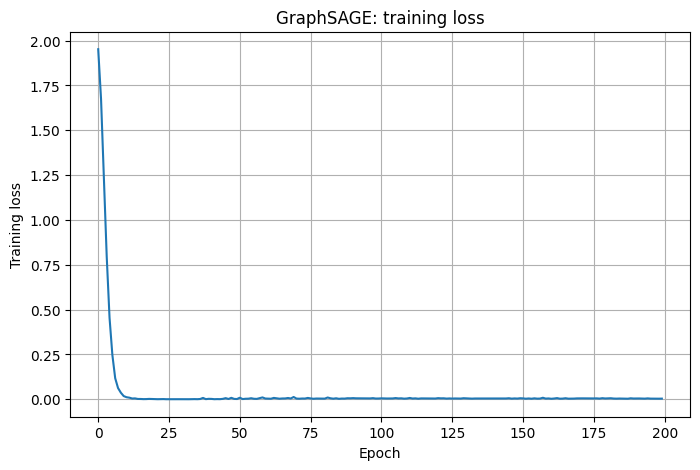

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history["loss"])
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("GraphSAGE: training loss")
plt.grid(True)
plt.show()

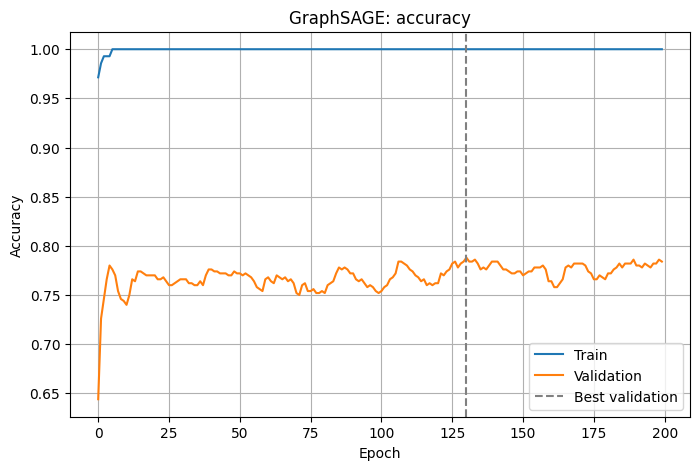

In [22]:
plt.figure(figsize=(8, 5))
plt.plot(history["train_acc"], label="Train")
plt.plot(history["val_acc"], label="Validation")
plt.axvline(best_epoch - 1, color="gray", linestyle="--", label="Best validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("GraphSAGE: accuracy")
plt.legend()
plt.grid(True)
plt.show()

As in Tutorials 4 and 5, training accuracy reaches 1.0 quickly while validation accuracy levels off. Exact curves vary with random initialisation and software versions.

# Part VI — Final test evaluation

## 21. Evaluate the best checkpoint on the test nodes

In [23]:
model.load_state_dict(best_state)

full_batch_test_acc = accuracy(model, data, data.test_mask)
print(f"Validation accuracy (best checkpoint): {accuracy(model, data, data.val_mask):.4f}")
print(f"Test accuracy:                         {full_batch_test_acc:.4f}")

Validation accuracy (best checkpoint): 0.7880
Test accuracy:                         0.8020


This is our **full-batch, transductive** result. In the next part, we change how the model sees the graph: first with sampled mini-batches, then with test nodes hidden during training.

# Part VII — Beyond full-batch, transductive training

## 22. A reusable training function

From here on, we train several models. To keep the code short, we wrap the loop from Section 19 in a function. It accepts a `train_step` so that we can plug in full-batch or mini-batch training.

In [24]:
def fit(model, train_step, eval_data, epochs=200, lr=0.01, weight_decay=5e-4):
    """Train with best-validation checkpointing. Returns (best_val_acc, test_acc)."""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_val, best_state = 0.0, None
    for _ in range(epochs):
        train_step(model, optimizer)
        val = accuracy(model, eval_data, eval_data.val_mask)
        if val > best_val:
            best_val, best_state = val, copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return best_val, accuracy(model, eval_data, eval_data.test_mask)

def full_batch_step(train_data):
    def step(model, optimizer):
        model.train()
        optimizer.zero_grad()
        logits = model(train_data.x, train_data.edge_index)
        loss = criterion(logits[train_data.train_mask], train_data.y[train_data.train_mask])
        loss.backward()
        optimizer.step()
    return step

## 23. Mini-batch training with neighbour sampling

Now we train using our sampler from Part III. In each epoch:

1. Shuffle the training nodes and split them into batches of seed nodes.
2. For each batch, sample a 2-hop subgraph with fan-outs $[10, 5]$.
3. Run the model on the **small subgraph** and compute the loss on the **seed nodes only**.

```text
for each batch of seeds:
    subgraph = sample_subgraph(seeds, fanouts=[10, 5])
    logits   = model(x[subgraph nodes], subgraph edges)
    loss     = CE(logits[:batch_size], y[seeds])
```

For validation and testing we still use the full graph — on Cora that is cheap, and it lets us compare directly with full-batch training.

In [25]:
def mini_batch_step(data, fanouts=(10, 5), batch_size=32):
    train_nodes = data.train_mask.nonzero().view(-1)

    def step(model, optimizer):
        model.train()
        perm = train_nodes[torch.randperm(train_nodes.numel(), device=train_nodes.device)]
        for seeds in perm.split(batch_size):
            node_ids, local_ei, bs = sample_subgraph(seeds, data.edge_index, data.num_nodes, fanouts)
            optimizer.zero_grad()
            logits = model(data.x[node_ids], local_ei)
            loss = criterion(logits[:bs], data.y[seeds])
            loss.backward()
            optimizer.step()
    return step

torch.manual_seed(7)
mb_model = GraphSAGE(dataset.num_node_features, 64, dataset.num_classes).to(device)
mb_val, mb_test = fit(mb_model, mini_batch_step(data), data, epochs=50)

print(f"Full-batch training:  test accuracy = {full_batch_test_acc:.4f}")
print(f"Mini-batch [10, 5]:   test accuracy = {mb_test:.4f}  (best val {mb_val:.4f})")

Full-batch training:  test accuracy = 0.8020
Mini-batch [10, 5]:   test accuracy = 0.8170  (best val 0.8020)


The mini-batch model reaches a similar accuracy, even though it never saw a full neighbourhood during training. Each epoch performs several optimizer updates (one per batch), so 50 epochs is enough here.

## 24. An inductive experiment: hide the test nodes

So far, test nodes were part of the graph during training — only their **labels** were hidden. Now we make it harder:

1. **Remove** all test nodes and every edge touching them.
2. Train on the remaining graph.
3. At inference, put the test nodes **back** and predict their labels.

```text
Training graph                       Inference graph
(test nodes and their edges removed)  (full graph)

   o──o      o                          o──o──●──o
   │  │      │                          │  │  │  │
   o──o──o   o          ──────▶         o──o──o──●
                                              ●  = never seen during training
```

The model has never seen these nodes or their edges. If it still classifies them well, it has learned a **rule** for combining features and neighbourhoods, not a memorised answer for each node.

In [26]:
from torch_geometric.data import Data
from torch_geometric.utils import subgraph

keep = ~data.test_mask
train_edge_index, _ = subgraph(keep, data.edge_index, relabel_nodes=True, num_nodes=data.num_nodes)

train_graph = Data(
    x=data.x[keep], edge_index=train_edge_index, y=data.y[keep],
    train_mask=data.train_mask[keep], val_mask=data.val_mask[keep],
)

print(f"Full graph:     {data.num_nodes} nodes, {data.num_edges} edges")
print(f"Training graph: {train_graph.num_nodes} nodes, {train_graph.num_edges} edges")
print(f"Edges removed:  {data.num_edges - train_graph.num_edges}")

Full graph:     2708 nodes, 10556 edges
Training graph: 1708 nodes, 4438 edges
Edges removed:  6118


We train on `train_graph` (selecting the checkpoint on its validation nodes), then evaluate on the **full** graph.

In [27]:
def fit_inductive(model, epochs=200):
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    step = full_batch_step(train_graph)
    best_val, best_state = 0.0, None
    for _ in range(epochs):
        step(model, optimizer)
        val = accuracy(model, train_graph, train_graph.val_mask)
        if val > best_val:
            best_val, best_state = val, copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return best_val, accuracy(model, data, data.test_mask)   # test on the FULL graph

torch.manual_seed(7)
ind_model = GraphSAGE(dataset.num_node_features, 64, dataset.num_classes).to(device)
ind_val, ind_test = fit_inductive(ind_model)

print(f"Transductive (test nodes in graph during training): {full_batch_test_acc:.4f}")
print(f"Inductive    (test nodes unseen during training):   {ind_test:.4f}")

Transductive (test nodes in graph during training): 0.8020
Inductive    (test nodes unseen during training):   0.7870


The accuracy on completely unseen nodes is close to the transductive result. GraphSAGE learned a function that transfers to new nodes.

What happens if a new node arrives **without** its edges? Then GraphSAGE can only use the node's own features — the neighbour aggregate is zero. Let's check.

In [28]:
# Keep only edges that do NOT touch a test node -> test nodes become isolated
src, dst = data.edge_index
no_test_edges = ~(data.test_mask[src] | data.test_mask[dst])
isolated_graph = Data(x=data.x, edge_index=data.edge_index[:, no_test_edges], y=data.y,
                      test_mask=data.test_mask)

print(f"Inductive, test nodes WITH their edges:    {accuracy(ind_model, data, data.test_mask):.4f}")
print(f"Inductive, test nodes WITHOUT their edges: {accuracy(ind_model, isolated_graph, data.test_mask):.4f}")

Inductive, test nodes WITH their edges:    0.7870
Inductive, test nodes WITHOUT their edges: 0.5170


Without edges, accuracy drops sharply. Inductive does not mean "context-free": a new node still needs its **features and neighbours** for the model to do its job.

# Part VIII — Inspect predictions and compare aggregators

## 25. Compare predicted and true labels on test nodes

In [29]:
model.eval()
with torch.no_grad():
    logits = model(data.x, data.edge_index)

probabilities = torch.softmax(logits, dim=1)
predictions = logits.argmax(dim=1)
test_ids = data.test_mask.nonzero(as_tuple=False).view(-1)[:15]

print("Node | True | Predicted | Confidence")
print("-------------------------------------")
for i in test_ids.tolist():
    pred = predictions[i].item()
    print(f"{i:4d} | {data.y[i].item():4d} | {pred:9d} | {probabilities[i, pred].item():10.3f}")

Node | True | Predicted | Confidence
-------------------------------------
1708 |    3 |         2 |      0.337
1709 |    2 |         2 |      0.987
1710 |    2 |         2 |      0.871
1711 |    2 |         2 |      0.999
1712 |    2 |         2 |      0.999
1713 |    0 |         2 |      0.274
1714 |    2 |         2 |      0.997
1715 |    2 |         2 |      0.999
1716 |    2 |         2 |      0.980
1717 |    2 |         2 |      0.999
1718 |    2 |         2 |      0.996
1719 |    2 |         2 |      0.998
1720 |    2 |         2 |      0.998
1721 |    2 |         2 |      0.998
1722 |    2 |         2 |      0.995


## 26. Compare aggregators on Cora

We now train the same model with mean, max, and sum aggregation, using **3 random seeds** each. Everything else stays fixed. Reporting the mean and standard deviation over seeds avoids reading too much into a single lucky run.

In [30]:
import statistics

results = {}
for aggr in ["mean", "max", "sum"]:
    test_accs = []
    for seed in range(3):
        torch.manual_seed(seed)
        m = GraphSAGE(dataset.num_node_features, 64, dataset.num_classes, aggr=aggr).to(device)
        _, test = fit(m, full_batch_step(data), data, epochs=200)
        test_accs.append(test)
    results[aggr] = test_accs
    print(f"aggr={aggr:4s} | test accuracy = {statistics.mean(test_accs):.4f} "
          f"± {statistics.stdev(test_accs):.4f}  {[round(a, 3) for a in test_accs]}")

aggr=mean | test accuracy = 0.8020 ± 0.0044  [0.8, 0.807, 0.799]
aggr=max  | test accuracy = 0.7653 ± 0.0071  [0.764, 0.759, 0.773]
aggr=sum  | test accuracy = 0.7720 ± 0.0243  [0.744, 0.784, 0.788]


On Cora, mean aggregation tends to do best. That matches the analysis from Section 6: for a paper's topic, the **proportion** of neighbours on each topic matters more than their **number**, and mean captures proportions. Sum is more sensitive to degree, and max keeps only feature-wise extremes. On other graphs — for example, molecules, where counting atoms matters — the ranking can change.

# 🧪 Hands-on Exercise 5 — Pooling aggregator on Cora

Train a `GraphSAGE` model with `SAGEConv(..., aggr="max", project=True)` in both layers. Does the learnable pooling aggregator beat plain max? Does it beat mean?

In [33]:
# TODO: build a pooling GraphSAGE model.

# class PoolGraphSAGE(GraphSAGE):
#     def __init__(self, input_dim, hidden_dim, output_dim, dropout=0.5):
#         super().__init__(input_dim, hidden_dim, output_dim, dropout)
#         self.conv1 = SAGEConv(input_dim, hidden_dim, aggr="max", project=True)
#         self.conv2 = SAGEConv(hidden_dim, output_dim, aggr="max", project=True)

# 🧪 Hands-on Exercise 6 — Fan-outs and batch size

Rerun the mini-batch experiment from Section 23 with fan-outs `[25, 10]`, `[5, 5]`, and `[2, 2]`, and batch sizes 16, 32, and 140.

Questions:
1. How small can the fan-out be before accuracy drops?
2. What is special about `batch_size=140`?

In [34]:
# TODO: vary fanouts and batch size.

# for fanouts in [(25, 10), (10, 5), (5, 5), (2, 2)]:
#     torch.manual_seed(7)
#     m = GraphSAGE(dataset.num_node_features, 64, dataset.num_classes).to(device)
#     _, test = fit(m, mini_batch_step(data, fanouts=fanouts), data, epochs=50)
#     print(fanouts, round(test, 4))

# 🧪 Hands-on Exercise 7 — Inductive GCN and GAT

Repeat the inductive experiment from Section 24 with the GCN from Tutorial 4 and the GAT from Tutorial 6.

Are they also inductive? (Hint: do `GCNConv` or `GATConv` store anything per node?) Which part of GraphSAGE's reputation for being "inductive" comes from the architecture, and which from how it is trained and evaluated?

In [35]:
# TODO: run the inductive experiment with GCNConv and GATConv.

# from torch_geometric.nn import GCNConv
# class GCN(nn.Module):
#     ...

# Part IX — From citation graphs to computational meshes

## 27. Why GraphSAGE fits meshes

| GraphSAGE idea | Mesh interpretation |
|---|---|
| Learned aggregation function | a learned local update rule for a cell or vertex |
| Inductive learning | apply the trained model to a **new mesh**: other resolution or geometry |
| Neighbour sampling / mini-batches | train on patches of very large meshes that do not fit in memory |
| Separate root weight $\mathbf W_1\mathbf h_i$ | a cell keeps its own state separate from the neighbour contribution |
| Mean aggregation | resembles averaging over neighbouring cells |

Mesh-based surrogate models are almost always **inductive**: they are trained on a set of simulations and applied to new geometries. A model that stored one embedding per mesh node would be useless for that.

However:
- Sampling neighbours on a mesh **changes the stencil**. A finite-volume update uses *all* faces of a cell. Random sampling is fine for regularisation, but not for a physically consistent operator.
- Mean aggregation ignores geometry. Face areas, distances, and normals must be added as edge features if the model should behave like a discretised operator.
- Generalisation across mesh resolutions is not automatic. Neighbour features at a fine resolution look different from those at a coarse one; training on several resolutions helps.

We will return to these questions in Tutorials 9 and 10.

# 🚀 Final Challenge — Learn a field on a mesh, then transfer it

Build a small inductive experiment inspired by heat transfer.

1. Create a 2D grid graph of $n\times n$ points with 4-neighbour connectivity.
2. Node features: normalised $x$, $y$, and a boundary indicator.
3. Target: a smooth field, e.g. $T(x,y)=\sin(\pi x)\sin(\pi y)$.
4. Train on a **coarse** grid ($n=8$), then evaluate on **finer** grids ($n=16$ and $n=32$) without retraining.

Compare:

| Model | Aggregator | MSE on 8×8 (train) | MSE on 16×16 | MSE on 32×32 |
|---|---|---:|---:|---:|
| MLP (features only) | — | ? | ? | ? |
| GraphSAGE | mean | ? | ? | ? |
| GraphSAGE | max | ? | ? | ? |
| GraphSAGE | sum | ? | ? | ? |

Questions:
- Which aggregator transfers best to finer grids? (Hint: on a 4-neighbour grid the degree stays the same, but the distance between neighbours shrinks — so neighbour features become more similar to the node's own.)
- What happens if you add the relative position $(x_j-x_i,\ y_j-y_i)$ to each message (see Tutorial 5, Exercise 7)?
- Visualise the target and predicted fields on the 32×32 grid. Where are the errors largest?

In [31]:
# Starter: build an n x n grid graph.

def grid_graph(n):
    idx = torch.arange(n * n).view(n, n)
    right = torch.stack([idx[:, :-1].reshape(-1), idx[:, 1:].reshape(-1)])
    down = torch.stack([idx[:-1, :].reshape(-1), idx[1:, :].reshape(-1)])
    edges = torch.cat([right, down], dim=1)
    edge_index = torch.cat([edges, edges.flip(0)], dim=1)       # both directions

    ys, xs = torch.meshgrid(torch.linspace(0, 1, n), torch.linspace(0, 1, n), indexing="ij")
    coords = torch.stack([xs.reshape(-1), ys.reshape(-1)], dim=1)
    boundary = ((coords == 0) | (coords == 1)).any(dim=1, keepdim=True).float()
    return torch.cat([coords, boundary], dim=1), edge_index

grid_x, grid_edge_index = grid_graph(8)
print("Grid node features:", grid_x.shape)
print("Grid edges:", grid_edge_index.shape)

# TODO 1: target = sin(pi x) * sin(pi y)
# TODO 2: train an MLP and GraphSAGE models (regression: MSELoss, output_dim=1)
# TODO 3: evaluate on grid_graph(16) and grid_graph(32) without retraining

Grid node features: torch.Size([64, 3])
Grid edges: torch.Size([2, 224])


### Completion checklist

- [ ] I can explain the difference between transductive and inductive learning.
- [ ] I can say what mean, max, and sum aggregation can and cannot distinguish.
- [ ] I implemented a pooling aggregator from scratch.
- [ ] I implemented neighbour sampling and a sampled mini-batch from scratch.
- [ ] I verified my layers against `SAGEConv`, including `project=True`.
- [ ] I trained GraphSAGE on Cora with full-batch and mini-batch training.
- [ ] I ran an inductive experiment with test nodes hidden during training.

# 28. Summary

We learned:
- the difference between transductive and inductive graph learning
- how mean, max, and sum aggregation differ, and what each one loses
- how to build a learnable pooling aggregator
- why the receptive field explodes with depth, and how neighbour sampling bounds it
- how to sample neighbours and build mini-batches with plain PyTorch
- that `SAGEConv` is exactly our layer, with `lin_r` for the node and `lin_l` for the neighbours
- how to train GraphSAGE full-batch and with mini-batches on Cora
- that GraphSAGE classifies nodes it never saw during training — as long as their features and edges are available

The key takeaway:

> GraphSAGE learns a **rule** for combining a node with its neighbours, not an answer for each node. That rule can be applied to sampled neighbourhoods, new nodes, and new graphs.

# 29. What comes next?

## Tutorial 8 — Graph-Level Learning

So far, every prediction has been for a **node**. Many problems need one prediction for a **whole graph**: is this molecule toxic? What is the drag coefficient of this mesh? Is this structure stable?

In the next tutorial, we add one new step after message passing:

```text
message passing (node embeddings)
    ↓
readout / pooling over all nodes   ← new
    ↓
one vector per graph
    ↓
graph classification or regression
```

We will also learn how PyG batches **many small graphs** into one mini-batch, a different kind of mini-batching from the neighbour sampling in this tutorial.

**Learn the graph. Understand the message passing. Build the model. Connect it to the physical world.**

---

## References
- Hamilton, W. L., Ying, R., & Leskovec, J. (2017). Inductive Representation Learning on Large Graphs. NeurIPS. https://arxiv.org/abs/1706.02216

- Xu, K., et al. (2019). How Powerful are Graph Neural Networks? ICLR. https://arxiv.org/abs/1810.00826

-- Rohit Raj $\cdot$ HalfQubiX